# T10: ranker v0 feature tables
Everything here reads the small tables in `data/` (written by `alias_check.py`, `alias_within_star.py` and `sanity.py`). The full candidate tables are in gitignored `runs/` and on the drive (see README).

In [1]:
import json
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
D = Path('data'); F = Path('figures')
RUNS = ['dev_medium_assigned', 'dev_medium_fullyear', 'train_1k']
pd.set_option('display.width', 160)

## 1. Alias features: diffrot vs correct (T10's required check)
Pooled over candidates. `alias_shift` = (median diffrot − median correct) / (median alias − median correct): 0 = diffrot looks like correct, 1 = looks like an alias.

In [2]:
for tag in ['t9_synthetic', 'smarts_dev_medium_fullyear']:
    r = pd.read_csv(D / f'{tag}_alias_check.csv')
    print(tag); display(r[r.group == 'all'][['feature','n_correct','n_diffrot','n_alias','auc_correct_vs_alias','auc_diffrot_vs_correct','alias_shift']].round(3))

t9_synthetic


,feature,n_correct,n_diffrot,n_alias,auc_correct_vs_alias,auc_diffrot_vs_correct,alias_shift
0,fold_half_corr,307,229,461,0.158,0.513,0.042
1,fold_half_corr_at_2P,307,229,460,0.805,0.428,0.299
2,acf_half_lag_contrast,307,229,461,0.871,0.429,0.408
3,acf_odd_even_contrast,307,229,451,0.674,0.547,-0.744
4,acf_height_at_P,307,229,461,0.755,0.522,-0.035
5,s_ph,307,229,459,0.542,0.546,-1.155
6,redchi_ratio_to_global_best,307,229,461,0.348,0.583,0.335


smarts_dev_medium_fullyear


,feature,n_correct,n_diffrot,n_alias,auc_correct_vs_alias,auc_diffrot_vs_correct,alias_shift
0,fold_half_corr,1284,864,2694,0.217,0.569,0.305
1,fold_half_corr_at_2P,1256,842,2587,0.784,0.381,0.451
2,acf_half_lag_contrast,1284,865,2694,0.811,0.375,0.675
3,acf_odd_even_contrast,1276,856,2664,0.734,0.471,0.188
4,acf_height_at_P,1284,865,2694,0.780,0.417,0.483
5,half_tooth_ratio,4,3,12,0.323,0.750,5.092
6,s_ph,1227,810,2428,0.508,0.463,9.723
7,redchi_ratio_to_global_best,1284,865,2694,0.381,0.525,0.189


In [3]:
r = pd.read_csv(D / 'smarts_dev_medium_fullyear_alias_check.csv')
r[r.feature.isin(['acf_half_lag_contrast','fold_half_corr_at_2P','acf_height_at_P'])].pivot(index='group', columns='feature', values='alias_shift').round(2)

feature,acf_half_lag_contrast,acf_height_at_P,fold_half_corr_at_2P
group,,,
1-3d,0.84,0.62,0.71
10-30d,0.46,0.37,0.19
3-10d,0.67,0.47,0.51
<1d,0.86,0.10,0.18
>30d,0.62,0.24,0.29
all,0.67,0.48,0.45


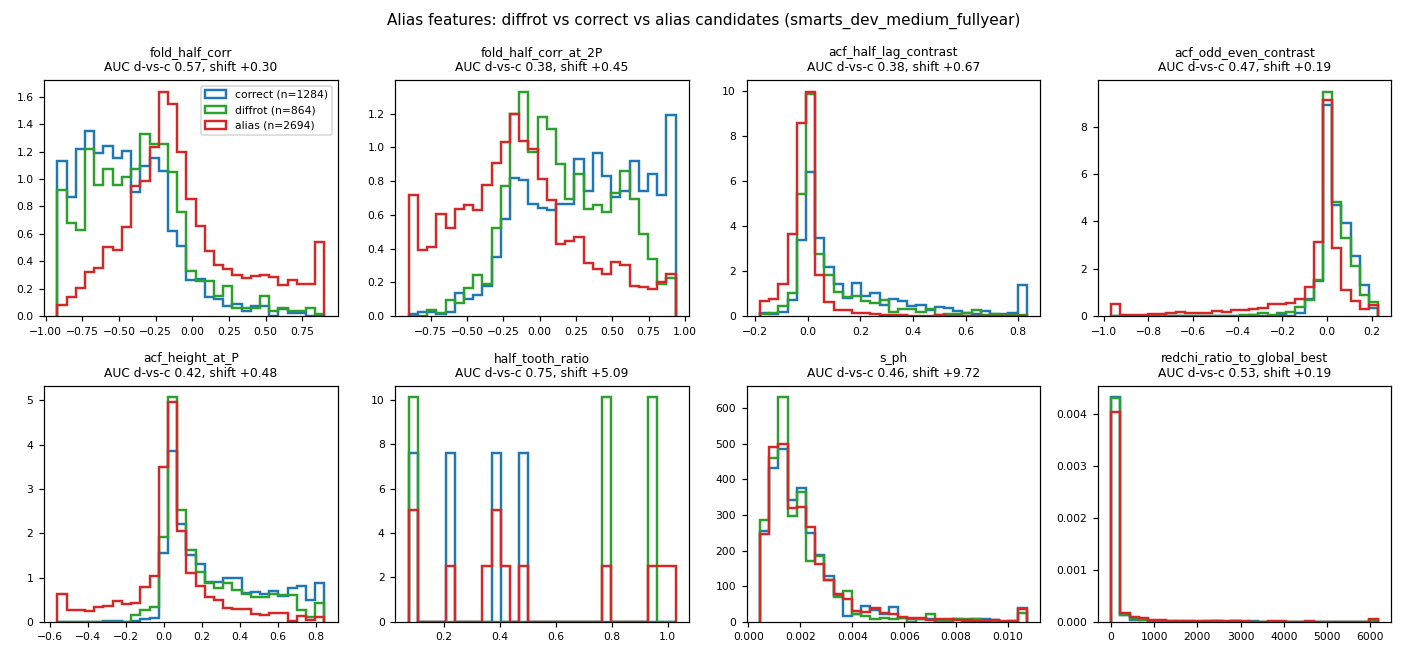

In [4]:
display(Image(F / 'fig_smarts_dev_medium_fullyear_alias_check.png'))

Within star (stars with both a fitted correct and a fitted diffrot candidate; best-redchi of each): the paired differences are ~0, so the pooled shift is mostly a star-level confound.

In [5]:
display(pd.read_csv(D / 'smarts_dev_medium_fullyear_alias_within_star.csv').round(3))
display(pd.read_csv(D / 'smarts_dev_medium_fullyear_gate_by_outcome.csv', index_col=0).round(3))

,feature,n_stars,median_diff,frac_diffrot_lower
0,fold_half_corr,243,-0.027,0.597
1,fold_half_corr_at_2P,239,0.000,0.498
2,acf_half_lag_contrast,243,-0.005,0.539
3,acf_odd_even_contrast,241,0.001,0.465
4,acf_height_at_P,243,0.000,0.305
5,redchi_ratio_to_global_best,243,0.117,0.469


,n,pass_half_lag,pass_all
outcome,,,
correct,1284,0.522,0.228
diffrot,865,0.316,0.095
double,1315,0.068,0.006
half,1379,0.094,0.015
wrong,17695,0.077,0.007


## 2. Label balance per period bin

dev_medium_assigned


,0,1,2,n,frac_0,frac_1,frac_2
period_bin,,,,,,,
<1d,3235,112,148,3495,0.925608,0.032046,0.042346
1-3d,3381,175,289,3845,0.879324,0.045514,0.075163
3-10d,3200,188,279,3667,0.872648,0.051268,0.076084
10-30d,3332,96,165,3593,0.927359,0.026719,0.045923
>30d,6339,72,111,6522,0.971941,0.011040,0.017019


dev_medium_fullyear


,0,1,2,n,frac_0,frac_1,frac_2
period_bin,,,,,,,
<1d,3841,55,81,3977,0.965803,0.013830,0.020367
1-3d,3563,159,248,3970,0.897481,0.040050,0.062469
3-10d,3597,251,343,4191,0.858268,0.059890,0.081842
10-30d,3763,209,300,4272,0.880852,0.048923,0.070225
>30d,7083,257,379,7719,0.917606,0.033294,0.049100


train_1k


,0,1,2,n,frac_0,frac_1,frac_2
period_bin,,,,,,,
<1d,3392,117,170,3679,0.921990,0.031802,0.046208
1-3d,3196,182,241,3619,0.883117,0.050290,0.066593
3-10d,3211,185,284,3680,0.872554,0.050272,0.077174
10-30d,3216,101,171,3488,0.922018,0.028956,0.049025
>30d,6260,89,125,6474,0.966945,0.013747,0.019308


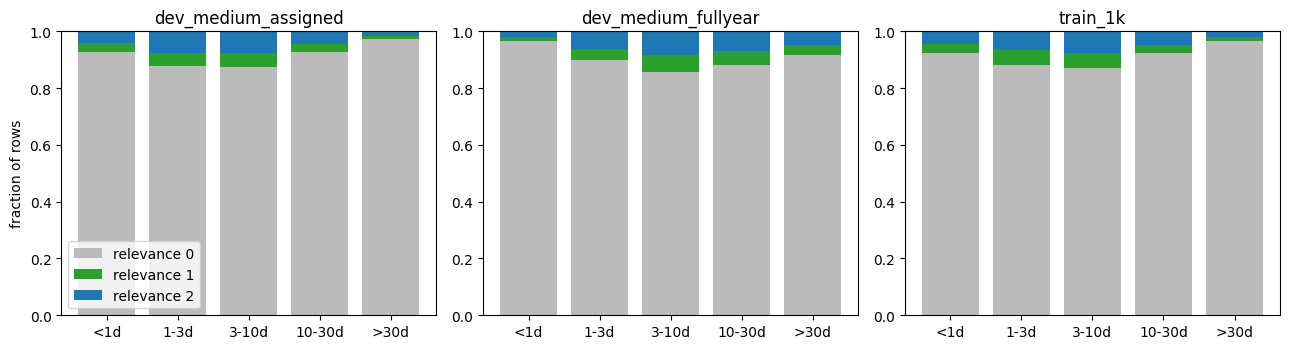

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cols = {0: '#bbbbbb', 1: '#2ca02c', 2: '#1f77b4'}
for ax, k in zip(axes, RUNS):
    lb = pd.read_csv(D / f'sanity_{k}_label_balance.csv', index_col=0)
    b = np.zeros(len(lb))
    for r in (0, 1, 2):
        ax.bar(lb.index, lb[f'frac_{r}'], bottom=b, color=cols[r], label=f'relevance {r}'); b += lb[f'frac_{r}'].values
    ax.set_title(k); ax.set_ylim(0, 1)
axes[0].legend(); axes[0].set_ylabel('fraction of rows'); plt.tight_layout()
for k in RUNS: print(k); display(pd.read_csv(D / f'sanity_{k}_label_balance.csv', index_col=0))

## 3. Candidates per star, and stars with any relevant candidate vs hand success

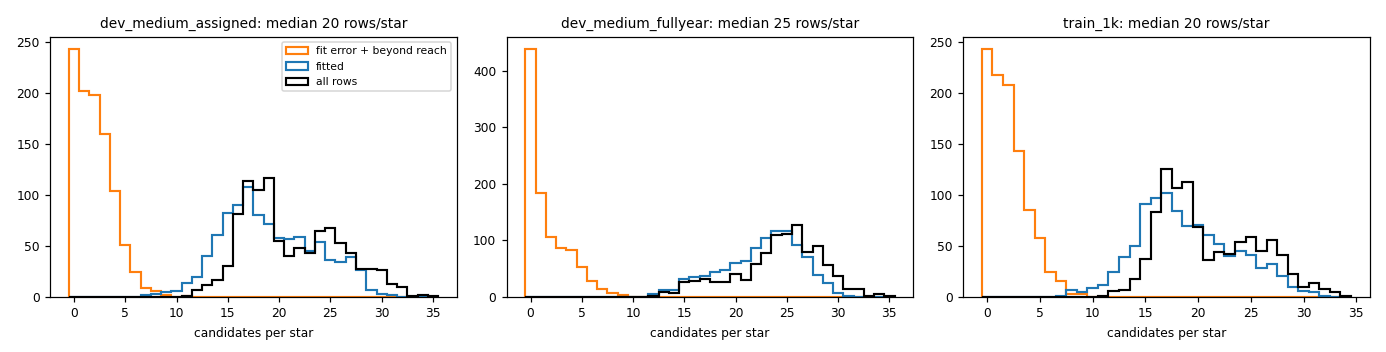

In [7]:
display(Image(F / 'fig_candidates_per_star.png'))

dev_medium_assigned


,n_stars,mean_rows,frac_any_rel,frac_any_rel_fitted,hand_success,frac_no_rows
period_bin,,,,,,
<1d,172.0,20.320,0.610,0.593,0.180,0.0
1-3d,172.0,22.355,0.878,0.878,0.227,0.0
3-10d,171.0,21.444,0.889,0.848,0.193,0.0
10-30d,171.0,21.012,0.643,0.520,0.175,0.0
>30d,314.0,20.771,0.264,0.191,0.048,0.0
all,1000.0,21.122,0.601,0.547,0.148,0.0


dev_medium_fullyear


,n_stars,mean_rows,frac_any_rel,frac_any_rel_fitted,hand_success,frac_no_rows
period_bin,,,,,,
<1d,172.0,23.122,0.337,0.326,0.169,0.0
1-3d,172.0,23.081,0.802,0.802,0.233,0.0
3-10d,171.0,24.509,0.942,0.942,0.298,0.0
10-30d,171.0,24.982,0.971,0.971,0.363,0.0
>30d,314.0,24.583,0.768,0.640,0.210,0.0
all,1000.0,24.129,0.764,0.722,0.248,0.0


train_1k


,n_stars,mean_rows,frac_any_rel,frac_any_rel_fitted,hand_success,frac_no_rows
period_bin,,,,,,
<1d,172.0,21.390,0.610,0.605,0.233,0.0
1-3d,172.0,21.041,0.895,0.895,0.215,0.0
3-10d,171.0,21.520,0.883,0.877,0.281,0.0
10-30d,171.0,20.398,0.637,0.503,0.193,0.0
>30d,314.0,20.618,0.261,0.204,0.064,0.0
all,1000.0,20.940,0.601,0.558,0.178,0.0


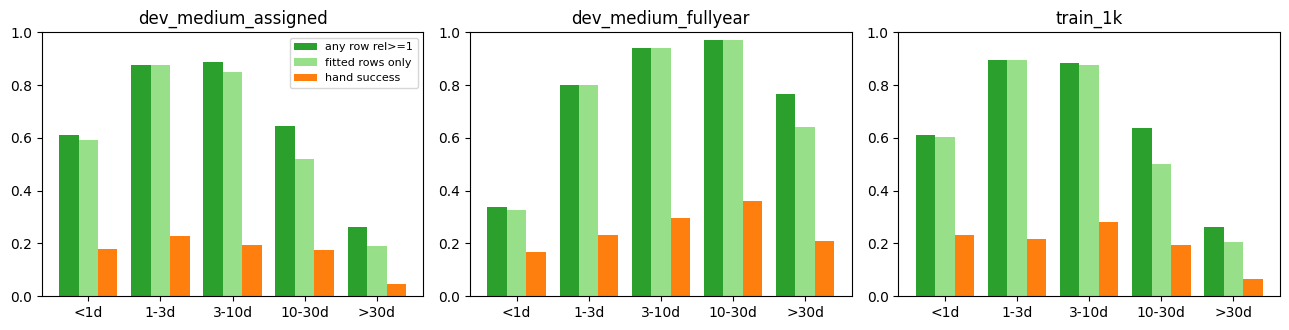

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, k in zip(axes, RUNS):
    ss = pd.read_csv(D / f'sanity_{k}_star_summary.csv', index_col=0).drop(index='all'); x = np.arange(len(ss))
    ax.bar(x-.27, ss.frac_any_rel, .27, label='any row rel>=1', color='#2ca02c')
    ax.bar(x, ss.frac_any_rel_fitted, .27, label='fitted rows only', color='#98df8a')
    ax.bar(x+.27, ss.hand_success, .27, label='hand success', color='#ff7f0e')
    ax.set_xticks(x, ss.index); ax.set_ylim(0, 1); ax.set_title(k)
axes[0].legend(fontsize=8); plt.tight_layout()
for k in RUNS: print(k); display(pd.read_csv(D / f'sanity_{k}_star_summary.csv', index_col=0).round(3))

## 4. Gate-failure rates (fitted rows; relevance >= 1 vs 0)

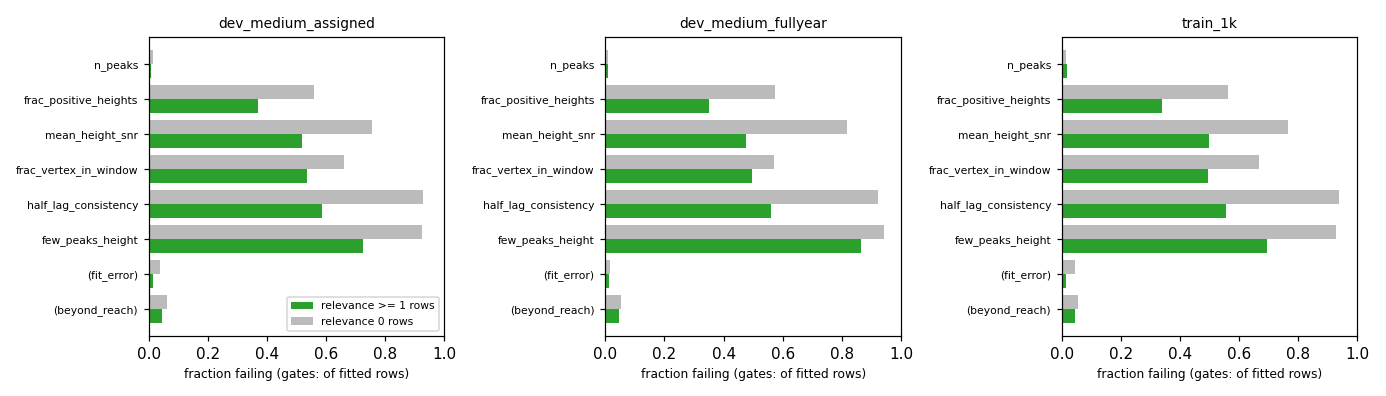

dev_medium_assigned


,gate,fail_all,fail_relevant,fail_irrelevant,n_relevant,sole_fail_relevant
0,n_peaks,0.014,0.008,0.015,1541,0.003
1,frac_positive_heights,0.544,0.371,0.559,1541,0.004
2,mean_height_snr,0.735,0.520,0.754,1541,0.036
3,frac_vertex_in_window,0.651,0.533,0.662,1541,0.084
4,half_lag_consistency,0.900,0.585,0.928,1541,0.018
5,few_peaks_height,0.906,0.723,0.923,224,0.107
6,(fit_error),0.037,0.014,0.039,1635,NaN
7,(beyond_reach),0.059,0.043,0.060,1635,NaN


dev_medium_fullyear


,gate,fail_all,fail_relevant,fail_irrelevant,n_relevant,sole_fail_relevant
0,n_peaks,0.008,0.009,0.007,2149,0.004
1,frac_positive_heights,0.552,0.349,0.574,2149,0.007
2,mean_height_snr,0.786,0.475,0.819,2149,0.048
3,frac_vertex_in_window,0.564,0.495,0.571,2149,0.098
4,half_lag_consistency,0.888,0.561,0.923,2149,0.016
5,few_peaks_height,0.936,0.866,0.941,202,0.139
6,(fit_error),0.014,0.011,0.014,2282,NaN
7,(beyond_reach),0.052,0.047,0.053,2282,NaN


train_1k


,gate,fail_all,fail_relevant,fail_irrelevant,n_relevant,sole_fail_relevant
0,n_peaks,0.014,0.016,0.014,1567,0.004
1,frac_positive_heights,0.544,0.338,0.562,1567,0.003
2,mean_height_snr,0.744,0.498,0.767,1567,0.040
3,frac_vertex_in_window,0.653,0.495,0.667,1567,0.092
4,half_lag_consistency,0.907,0.556,0.939,1567,0.015
5,few_peaks_height,0.904,0.695,0.928,285,0.119
6,(fit_error),0.041,0.014,0.043,1665,NaN
7,(beyond_reach),0.055,0.044,0.055,1665,NaN


In [9]:
display(Image(F / 'fig_gate_failure.png'))
for k in RUNS: print(k); display(pd.read_csv(D / f'sanity_{k}_gate_failure.csv', index_col=0).round(3))

## 5. Parity: the selected row reproduces the scorecard's final answer

In [10]:
p = json.load(open(D / 'parity.json'))
pd.DataFrame(p).T[['n_stars','n_success','n_success_with_one_selected_row','n_declined_with_selected_row','max_rel_diff_selected_vs_final','n_same_success_flag','n_period_identical','n_same_outcome','n_rows','n_errors']]

,n_stars,n_success,n_success_with_one_selected_row,n_declined_with_selected_row,max_rel_diff_selected_vs_final,n_same_success_flag,n_period_identical,n_same_outcome,n_rows,n_errors
dev_medium_assigned,1000,211,211,0,0.0,1000,211,1000,21122,0
dev_medium_fullyear,1000,350,350,0,0.0,1000,350,1000,24129,0
train_1k,1000.0,200.0,200.0,0.0,0.0,NaN,NaN,NaN,20940.0,0.0
